# Customer Churn Prediction - Telecom
## Exploratory Data Analysis


## The business problem

A telecom company is losing customers. Leadership's question 
is simple:

**Customers keep leaving.who are they, why are they leaving,
and what can we do about it before it costs us more?**


Keeping an existing customer is far cheaper than winning a new one, so a small drop in churn is worth real money. But
"why is churn happening?" is too big to answer with a single chart

## Ho i thought about the problem

A retention team has to make three decisions:
**Who** should we target?
**What** should we offer them(and when)?
**How much** is a stake , so we know ho much to spend?

So i broke the big problem into smaller questions . Each question is answered by one analysis, and each answer feeds 
one of those three decisions.



| # | Question | Why the business cares |
|---|---|---|
| Q0 | Can I trust the data? | Bad data gives confident but wrong answers |
| Q1 | How big is the problem? | Sets the baseline and the budget |
| Q2 | Do new or long-standing customers leave? | Tells us *when* to intervene |
| Q3 | Does price play a role? | Decides whether discounts could help |
| Q4 | Does contract type matter? | Points to the biggest retention lever |
| Q5 | Which services keep customers? | Tells us *what* to offer |
| Q6 | Does the way customers pay matter? | Cheap early-warning signals |
| Q7 | Which customer groups are most at risk? | Tells us *who* to target |
| Q8 | Where do the risks combine? | Produces a short, actionable priority list |
| Q9 | Are these patterns real or just chance? | Stops us acting on noise |
| Q10 | What must I remember when I build the model? | Carries the learning into modeling |

**How each section is written:** Question (what I am doing and why) → Analysis → Finding → So what.

**Input:** `data/processed/cleaned_churn.csv` (output of the data cleaning notebook)

## Setup
### Load the libraries needed to analyze and visualize the data.

## Setup and data loading

**What:** import the libraries, define a few helpers, and load the cleaned data.

**Why:** every chart in this notebook answers a churn question, so I define the churn flag and the company-wide churn rate once. Every later chart is judged against that baseline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression





df = pd.read_csv(r"D:\Projects\notebooks\Churn_Prediction_Project\data\processed\cleaned_churn.csv")
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Q0. Can I trust the data?

**What:** check size, missing values, duplicates and the range of the numeric columns.

**Why:** if the data is broken, every insight after this is wrong. A two-minute check protects the whole analysis.

In [5]:
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1] - 1} (excluding the ChurnFlag I added)")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Rows identical across every column: {df.duplicated().sum()}")


numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[numeric_cols].describe().round(1)

Rows: 7,032  |  Columns: 19 (excluding the ChurnFlag I added)
Missing values: 0
Rows identical across every column: 22


,tenure,MonthlyCharges,TotalCharges
count,7032.0,7032.0,7032.0
mean,32.4,64.8,2283.3
std,24.5,30.1,2266.8
min,1.0,18.2,18.8
25%,9.0,35.6,401.4
50%,29.0,70.4,1397.5
75%,55.0,89.9,3794.7
max,72.0,118.8,8684.8



Finding: the data is complete: 7,032 customers, 19 features plus the churn label, and no missing values. Tenure runs from 1 to 72 months, so I have new and long-standing customers to compare.

22 rows (0.3%) are identical across all columns. I kept them: the customer ID was removed during cleaning, so these are most likely different customers with the same profile, which is normal when most columns are categories.

So what: the data is reliable enough to analyze. I can move on to the real questions.

## Q1. How big is the problem?
**What:** count churned vs. retained customer and measure
how much monthly billing sits with the customers who left


**why:** leadership needs the size of the problem before deciding how much to invest. This churn rate is also the 
**baseline** . Any group abobe it is riskier than average

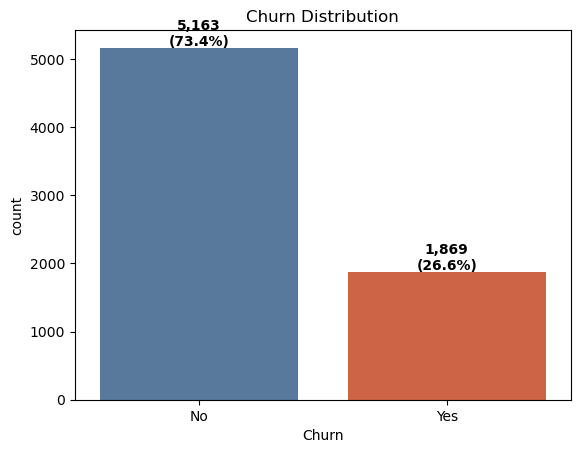

In [7]:
RETAINED, CHURNED = "#4C78A8", "#E4572E"

ax = sns.countplot(data=df, x="Churn", hue="Churn",
                    palette={"No": RETAINED, "Yes": CHURNED}, legend=False)

total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    pct = count / total * 100
    ax.text(p.get_x() + p.get_width()/2, p.get_height() + 30,
            f"{count:,}\n({pct:.1f}%)", ha="center", fontweight="bold")

ax.set_title("Churn Distribution")
plt.show()

**Finding:** **26.6% of customers churned, roughly 1 in 4** (1,869 customers). Those customers represent about **30.5% of total monthly charges**, which is more than their 26.6% share of headcount. We are losing customers who pay *above average*.

**So what:** this is a serious, revenue-relevant problem worth investing in. From here on, 26.6% is my yardstick.



---
## Q2. Do new or long-standing customers leave?

**What:** compare the tenure (months as a customer) of churned vs. retained customers, then measure churn rate across tenure groups.

**Why:** the answer tells us *when* to intervene. If customers leave early, we need better onboarding. If they leave late, we need loyalty offers.

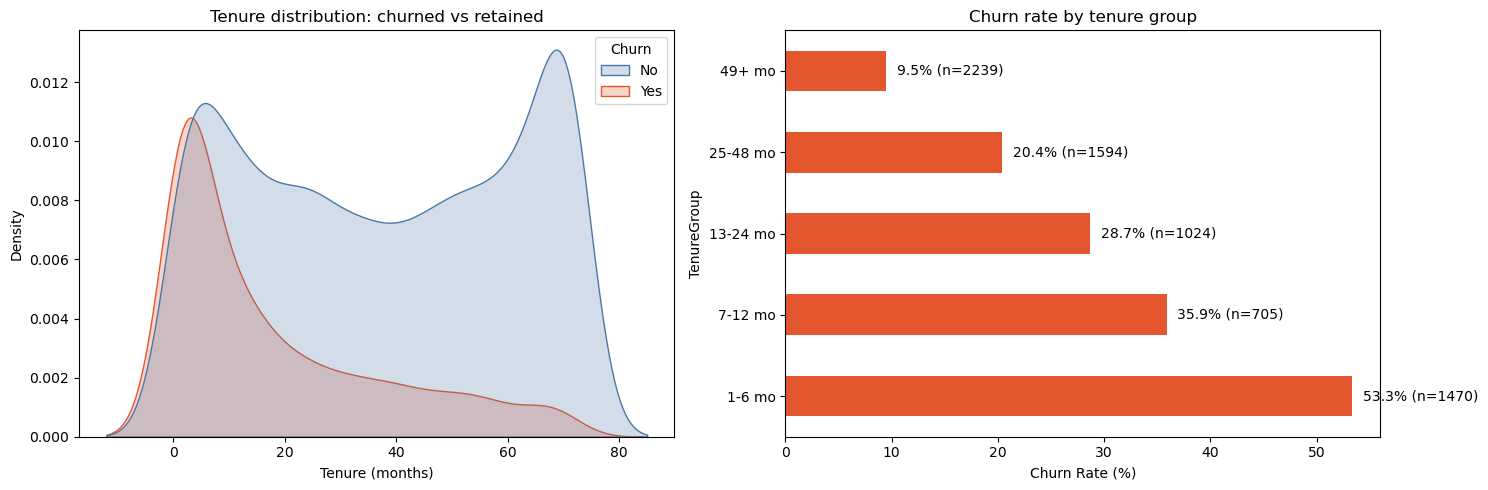

In [27]:
RETAINED, CHURNED = "#4C78A8", "#E4572E"


df[["tenure","TenureGroup"]].head(10)
result = df.groupby("TenureGroup", observed=True)["ChurnFlag"].agg(rate="mean", n="size")
result["rate"] = result["rate"] * 100
result = result.loc[tenure_order]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Pahilа chart -> daविकडे (axes[0])
sns.kdeplot(data=df, x="tenure", hue="Churn", fill=True,
            palette={"No": RETAINED, "Yes": CHURNED}, ax=axes[0])
axes[0].set_title("Tenure distribution: churned vs retained")
axes[0].set_xlabel("Tenure (months)")

# Duसरा chart -> उजवीकडे (axes[1])
result["rate"].plot(kind="barh", color=CHURNED, ax=axes[1])
for i, (rate, n) in enumerate(zip(result["rate"], result["n"])):
    axes[1].text(rate + 1, i, f"{rate:.1f}% (n={n})", va="center")
axes[1].set_title("Churn rate by tenure group")
axes[1].set_xlabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

**Finding:** churn is an **early-life problem**. Churned customers have a median tenure of just 10 months vs. 38 for retained ones. Churn rate falls steadily with tenure: **53.3% in months 1-6, down to 9.5% after 49 months**. The first 12 months hold only 30.9% of customers but **55.5% of all churners**.

**So what:** the biggest window for saving customers is the first year, especially the first six months. Retention effort should be front-loaded: onboarding, early check-ins, first-bill support.

## Q3. Does price play a role?

**What:** compare monthly charges and total charges for churned vs. retained customers.

**Why:** if price drives churn, discounts could help. If it does not, discounts would waste money.

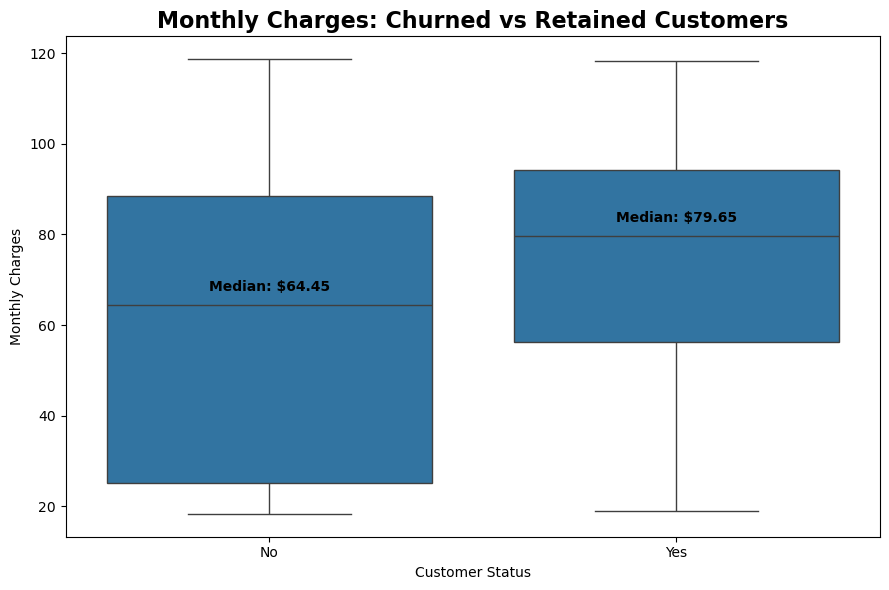

In [54]:


plt.figure(figsize=(9, 6))

ax = sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title(
    'Monthly Charges: Churned vs Retained Customers',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Customer Status')
plt.ylabel('Monthly Charges')

# Add median values
medians = df.groupby('Churn')['MonthlyCharges'].median()

for i, value in enumerate(medians.values):
    ax.text(
        i,
        value + 3,
        f'Median: ${value:.2f}',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


###  Finding

* Median MonthlyCharges: **Retained ≈ ₹64.5**, **Churned ≈ ₹79.6**
* Churned customers generally pay **higher monthly charges**.

###  Insight

* Higher monthly charges are **associated with higher churn**.
* TotalCharges is strongly affected by tenure, so **MonthlyCharges is more useful for this comparison**.

###  Business Implication

* Consider **targeted discounts or value-based offers** for high-charge customers, rather than discounts for everyone.


---
## Q4. Does contract type matter?

**What:** compare churn rates across month-to-month, one-year and two-year contracts, and check how much of the churn each contract type produces.

**Why:** a contract is a commitment. If it strongly affects churn, moving customers to longer contracts becomes an obvious lever.

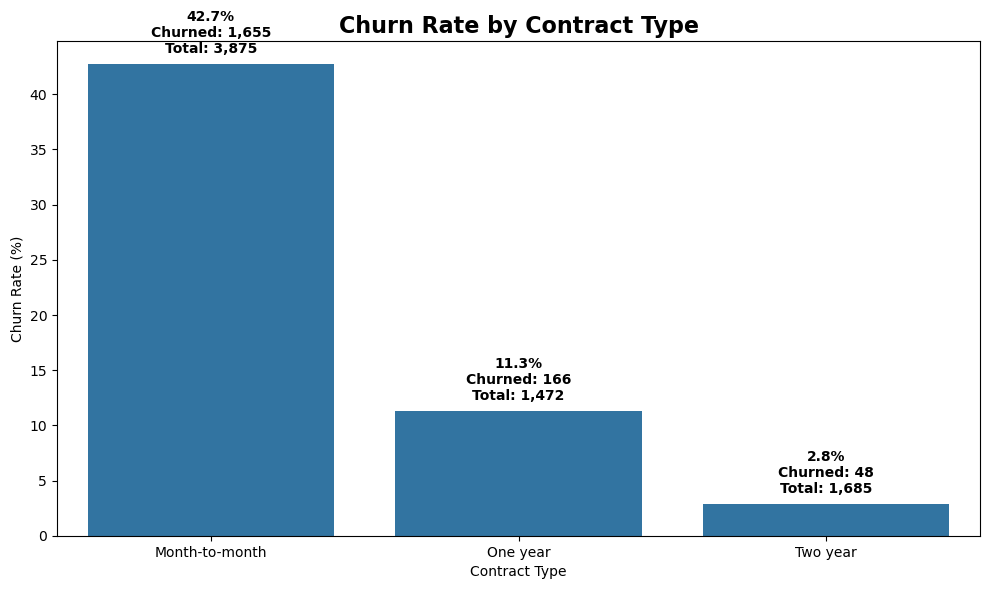

In [51]:
# Contract-level churn analysis

contract_analysis = (
    df.groupby('Contract')
      .agg(
          Total_Customers=('Contract', 'size'),
          Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
      )
      .reset_index()
)

# Customer share
contract_analysis['Customer_Share_%'] = (
    contract_analysis['Total_Customers']
    / contract_analysis['Total_Customers'].sum() * 100
)

# Churn rate within each contract type
contract_analysis['Churn_Rate_%'] = (
    contract_analysis['Churned_Customers']
    / contract_analysis['Total_Customers'] * 100
)

# Share of all churners
contract_analysis['Churn_Share_%'] = (
    contract_analysis['Churned_Customers']
    / contract_analysis['Churned_Customers'].sum() * 100
)

# Sort by churn rate
contract_analysis = contract_analysis.sort_values(
    'Churn_Rate_%',
    ascending=False
)

contract_analysis


contract_analysis.style.format({
    'Total_Customers': '{:,.0f}',
    'Churned_Customers': '{:,.0f}',
    'Customer_Share_%': '{:.1f}%',
    'Churn_Rate_%': '{:.1f}%',
    'Churn_Share_%': '{:.1f}%'
})


plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=contract_analysis,
    x='Contract',
    y='Churn_Rate_%'
)

plt.title('Churn Rate by Contract Type',
          fontsize=16, fontweight='bold')

plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

for i, row in contract_analysis.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row['Churn_Rate_%'] + 1,
        f"{row['Churn_Rate_%']:.1f}%\n"
        f"Churned: {row['Churned_Customers']:,}\n"
        f"Total: {row['Total_Customers']:,}",
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

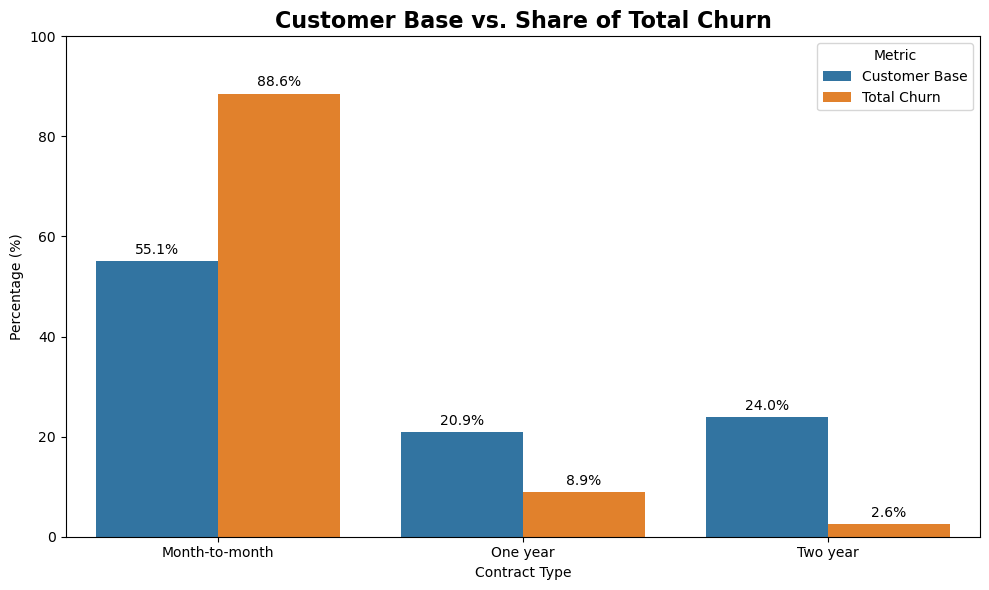

In [52]:
comparison = contract_analysis.melt(
    id_vars='Contract',
    value_vars=['Customer_Share_%', 'Churn_Share_%'],
    var_name='Metric',
    value_name='Percentage'
)

comparison['Metric'] = comparison['Metric'].replace({
    'Customer_Share_%': 'Customer Base',
    'Churn_Share_%': 'Total Churn'
})

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=comparison,
    x='Contract',
    y='Percentage',
    hue='Metric'
)

plt.title('Customer Base vs. Share of Total Churn',
          fontsize=16, fontweight='bold')

plt.xlabel('Contract Type')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3
    )

plt.tight_layout()
plt.show()

###  Finding

Month-to-month: **42.7% churn** vs **11.3% one-year** and **2.8% two-year**. They make up **55.1% of customers but 88.6% of churners**.

###  Insight

Longer contracts are **strongly associated with lower churn**.

###  Business Implication

Focus retention efforts on **month-to-month customers** and encourage longer-term plans.




---
## Q5. Which services keep customers?

**What:** (a) compare churn across internet service types, and (b) among customers who have internet, compare those *with* and *without* each add-on service.

**Why:** this tells us *what to offer*. I limit the add-on comparison to internet customers, because customers without internet cannot have these add-ons, and mixing them in would make the comparison unfair.


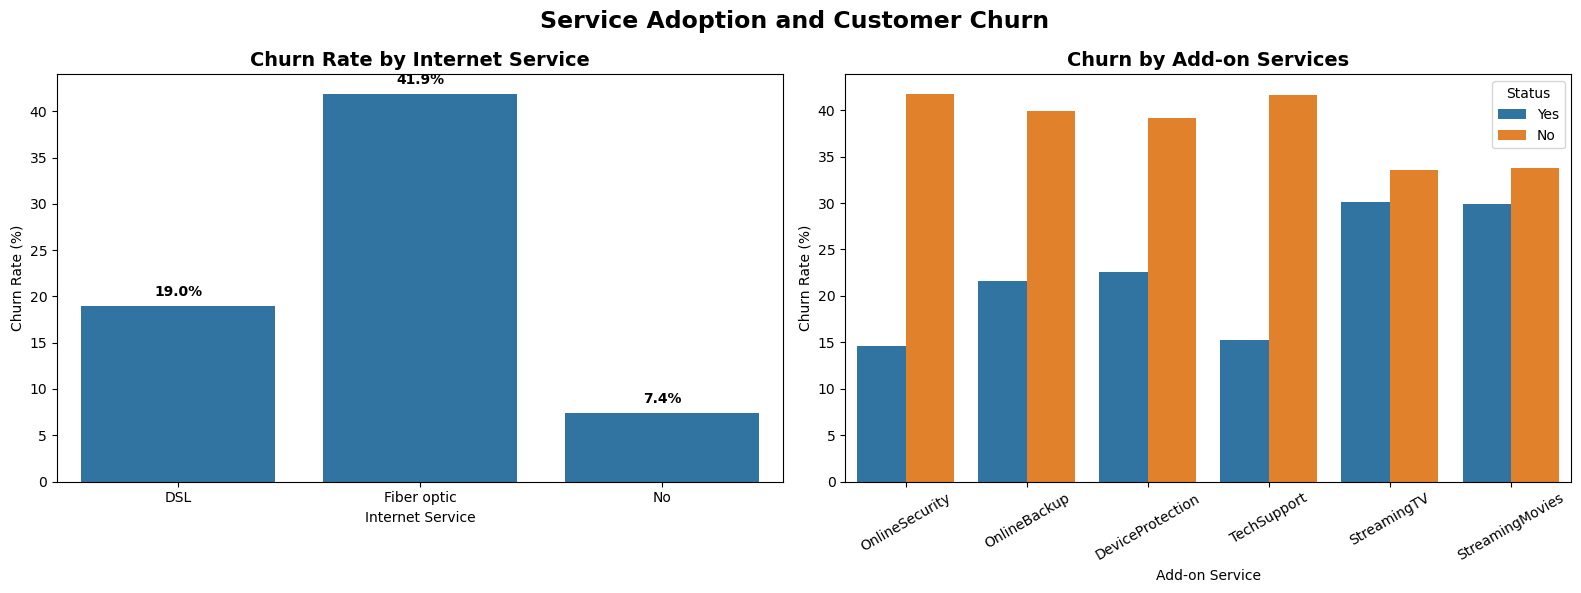

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ─────────────────────────────
# 1. Internet Service vs Churn
# ─────────────────────────────

internet_churn = (
    df.groupby('InternetService')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

sns.barplot(
    data=internet_churn,
    x='InternetService',
    y='Churn_Rate',
    ax=axes[0]
)

axes[0].set_title('Churn Rate by Internet Service',
                  fontsize=14, fontweight='bold')
axes[0].set_xlabel('Internet Service')
axes[0].set_ylabel('Churn Rate (%)')

for i, row in internet_churn.iterrows():
    axes[0].text(
        i,
        row['Churn_Rate'] + 1,
        f"{row['Churn_Rate']:.1f}%",
        ha='center',
        fontweight='bold'
    )


# ─────────────────────────────
# 2. Add-on Services vs Churn
# ─────────────────────────────

internet_df = df[df['InternetService'] != 'No'].copy()

addons = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

addon_churn = []

for service in addons:
    for status in ['Yes', 'No']:

        subset = internet_df[internet_df[service] == status]

        addon_churn.append({
            'Service': service,
            'Status': status,
            'Churn_Rate': subset['Churn'].eq('Yes').mean() * 100
        })

addon_churn = pd.DataFrame(addon_churn)

sns.barplot(
    data=addon_churn,
    x='Service',
    y='Churn_Rate',
    hue='Status',
    ax=axes[1]
)

axes[1].set_title('Churn by Add-on Services',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Add-on Service')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle(
    'Service Adoption and Customer Churn',
    fontsize=17,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


**Key Finding:** Fiber optic customers have the highest churn (~42%), while customers with add-on services show lower churn.

**Key Insight:** Higher service engagement is associated with lower churn, while Fiber customers need closer retention analysis.


**Insight:** customers without OnlineSecurity or TechSupport churn more.
**Business action:** these add-ons could be positioned as retention tools,
not just upsells.

## Payment Method vs.Churn
check if how customers pay relates to churn.


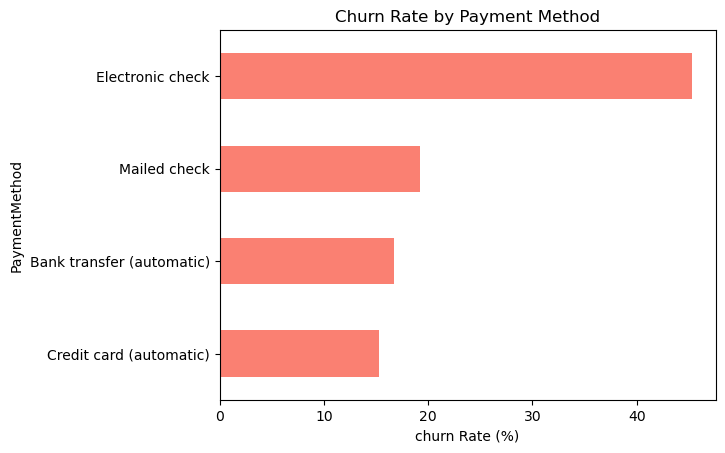

In [59]:
ct = pd.crosstab(df["PaymentMethod"],df["Churn"],normalize="index")*100
ct = ct.sort_values("Yes", ascending= False)
ax = ct["Yes"].plot(kind="barh" ,color="salmon")
ax.set_xlabel("churn Rate (%)")
ax.set_title("Churn Rate by Payment Method")
plt.gca().invert_yaxis()
plt.show()


हो, पण **“payment method strongly influences”** ऐवजी professional EDA मध्ये **“is strongly associated with churn”** म्हणणे योग्य.

###  Key Finding

**Electronic check** customers have the highest churn (~45%), while **automatic payment methods** have lower churn (~15–18%).

###  Key Insight

**Manual payment methods are associated with higher churn, while auto-pay customers show lower churn.**

###  Business Implication

**Encourage auto-pay adoption and target electronic-check customers for retention.**


In [ ]:
sample_df = df.sample(n=800, random_state=42)

sns.pairplot(
    sample_df,
    vars=numerical_cols,
    hue="Churn",
    palette="Set2",
    plot_kws={"alpha": 0.5, "s": 20},
)
plt.suptitle("Pairwise Relationships Between Numeric Features", y=1.02)
plt.show()

---
## Q7. Which customer groups are most at risk?

**What:** compare churn across gender, senior citizen status, partner and dependents.

**Why:** knowing *who* is vulnerable helps tailor the message and the offer. Just as important, it tells me which attributes I should *not* use for targeting.

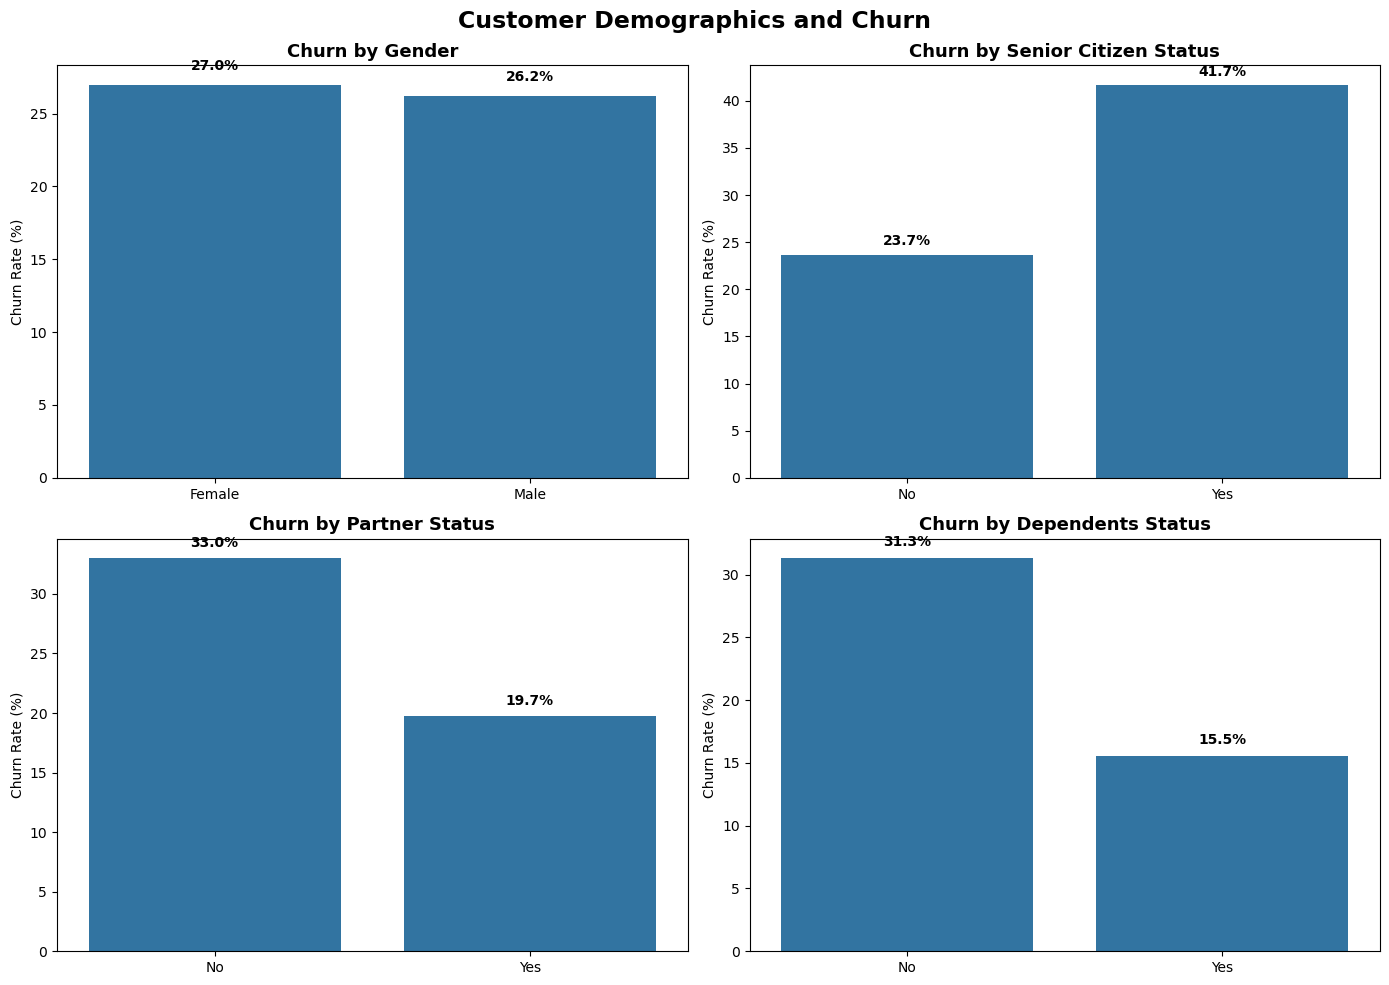

In [60]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']
titles = ['Churn by Gender',
          'Churn by Senior Citizen Status',
          'Churn by Partner Status',
          'Churn by Dependents Status']

for ax, feature, title in zip(axes.flat, features, titles):

    churn_rate = (
        df.groupby(feature)['Churn']
          .apply(lambda x: (x == 'Yes').mean() * 100)
          .reset_index(name='Churn_Rate')
    )

    sns.barplot(
        data=churn_rate,
        x=feature,
        y='Churn_Rate',
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Churn Rate (%)')

    # Add percentage labels
    for i, row in churn_rate.iterrows():
        ax.text(
            i,
            row['Churn_Rate'] + 1,
            f"{row['Churn_Rate']:.1f}%",
            ha='center',
            fontweight='bold'
        )

plt.suptitle(
    'Customer Demographics and Churn',
    fontsize=17,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

**Finding:**
- **Senior citizens** churn at **41.7% vs. 23.7%** (about 16% of the base).
- Customers **without a partner** churn at 33.0% (vs. 19.7%), and **without dependents** at 31.3% (vs. 15.5%). Customers with *neither* churn at 34.2%; those with *both* at just 14.3%. Customers with fewer household ties appear to leave more easily.
- **Gender makes no difference** (27.0% vs. 26.2%).

**So what:** senior and single-person households deserve tailored retention outreach. Gender carries no signal, so it should not be used for targeting.

---
## Q8. Where do the risks combine?

**What:** cross contract type with tenure group, then build a small "highest-risk segment" from the strongest signals found so far.

**Why:** single factors tell a story, but the retention team needs a **short, concrete list** of customers to act on. Risks usually stack, so combinations should reveal a much sharper target.

C:\Users\ganes\AppData\Local\Temp\ipykernel_17872\1136558828.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['Contract', 'TenureGroup'])['ChurnFlag']


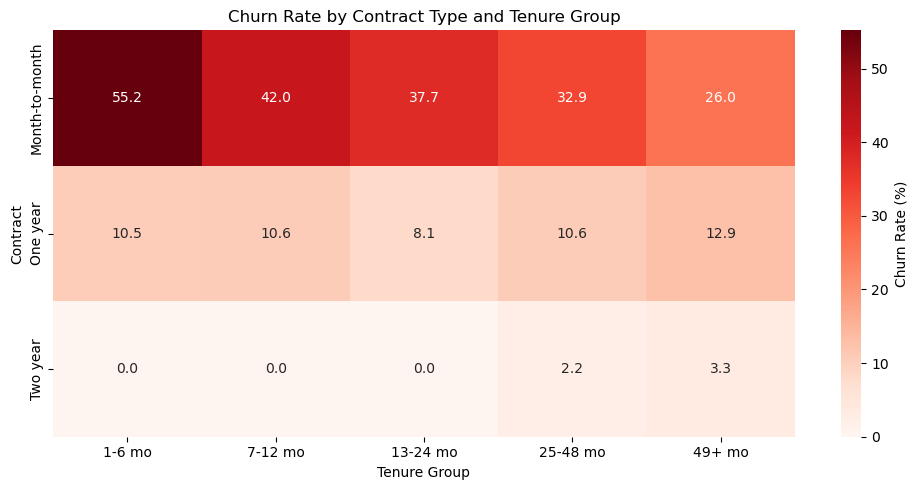

Month-to-month + First 12 Months
Customers: 1994
Churn Rate: 51.4 %

Month-to-month + First 12 Months + Fiber
Customers: 916
Churn Rate: 70.2 %


In [61]:
# 1. Calculate churn rate by Contract and Tenure Group
churn_rate = (
    df.groupby(['Contract', 'TenureGroup'])['ChurnFlag']
      .mean() * 100
)

# Convert to table
churn_rate = churn_rate.unstack()

# Keep contract order
churn_rate = churn_rate.loc[
    ['Month-to-month', 'One year', 'Two year']
]

# 2. Plot heatmap
plt.figure(figsize=(10, 5))

sns.heatmap(
    churn_rate,
    annot=True,
    fmt='.1f',
    cmap='Reds',
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title('Churn Rate by Contract Type and Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Contract')

plt.tight_layout()
plt.show()


# 3. Month-to-month + first 12 months
segment = df[
    (df['Contract'] == 'Month-to-month') &
    (df['tenure'] <= 12)
]

print("Month-to-month + First 12 Months")
print("Customers:", len(segment))
print("Churn Rate:", round(segment['ChurnFlag'].mean() * 100, 1), "%")


# 4. Month-to-month + first 12 months + Fiber
segment_fiber = df[
    (df['Contract'] == 'Month-to-month') &
    (df['tenure'] <= 12) &
    (df['InternetService'] == 'Fiber optic')
]

print("\nMonth-to-month + First 12 Months + Fiber")
print("Customers:", len(segment_fiber))
print("Churn Rate:", round(segment_fiber['ChurnFlag'].mean() * 100, 1), "%")

### Q9. Are these patterns real or just chance?

**What:** Use statistical tests to check whether categorical and numerical features are significantly related to churn. Use **Cramér’s V** to measure relationship strength.

**Why:** A chart may show a difference by chance. **p < 0.05** suggests a statistically significant relationship, while **Cramér’s V** shows how strong that relationship is.


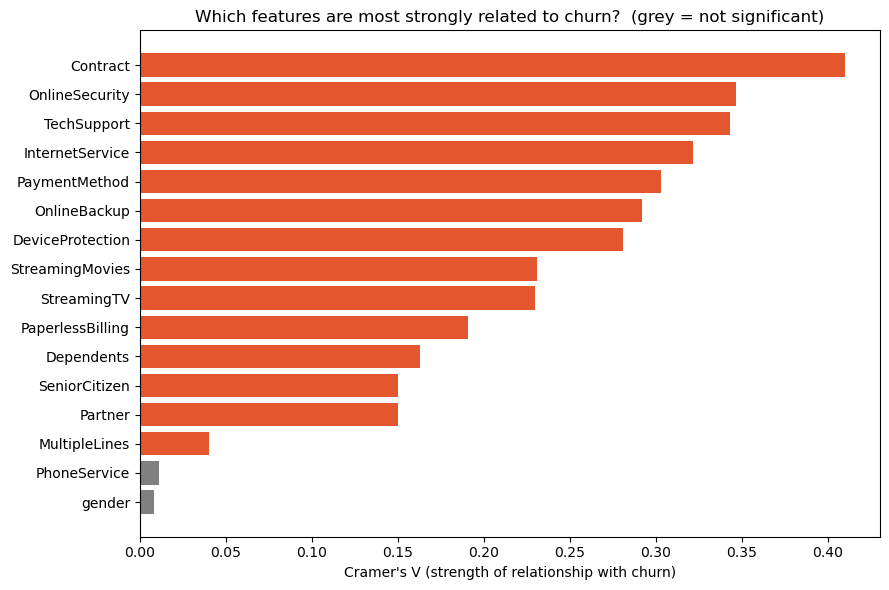

Significant features: 14 of 16

         Feature  Cramer's V   p_value  Significant (p<0.05)
        Contract       0.410 7.33e-257                  True
  OnlineSecurity       0.347 1.40e-184                  True
     TechSupport       0.343 7.41e-180                  True
 InternetService       0.322 5.83e-159                  True
   PaymentMethod       0.303 1.43e-139                  True
    OnlineBackup       0.292 7.78e-131                  True
DeviceProtection       0.281 1.96e-121                  True
 StreamingMovies       0.231  5.35e-82                  True
     StreamingTV       0.230  1.32e-81                  True
PaperlessBilling       0.191  8.24e-58                  True
      Dependents       0.163  2.02e-42                  True
   SeniorCitizen       0.150  2.48e-36                  True
         Partner       0.150  3.97e-36                  True
   MultipleLines       0.040  3.57e-03                  True
    PhoneService       0.011  3.50e-01               

,Feature,Mean (churned),Mean (retained),p_value
0,tenure,18.0,37.7,2.35e-234
1,MonthlyCharges,74.4,61.3,2.66e-72
2,TotalCharges,1531.8,2555.3,1.15e-75


In [63]:
cat_cols = [c for c in df.columns if c not in numeric_cols + ["Churn", "ChurnFlag", "TenureGroup"]]

rows = []
for col in cat_cols:
    table = pd.crosstab(df[col], df["Churn"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"Feature": col, "Cramer's V": round(v, 3), "p_value": p, "Significant (p<0.05)": p < 0.05})
chi_df = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
colors = [CHURNED if s else "grey" for s in chi_df["Significant (p<0.05)"]]
ax.barh(chi_df["Feature"], chi_df["Cramer's V"], color=colors)
ax.invert_yaxis()
ax.set_xlabel("Cramer's V (strength of relationship with churn)")
ax.set_title("Which features are most strongly related to churn?  (grey = not significant)")
plt.tight_layout()
plt.show()

chi_df["p_value"] = chi_df["p_value"].map(lambda x: f"{x:.2e}")
print(f"Significant features: {(chi_df['Significant (p<0.05)']).sum()} of {len(chi_df)}\n")
print(chi_df.to_string(index=False))

rows = []
for col in numeric_cols:
    a = df.loc[df["ChurnFlag"] == 1, col]
    b = df.loc[df["ChurnFlag"] == 0, col]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    rows.append({"Feature": col, "Mean (churned)": round(a.mean(), 1),
                 "Mean (retained)": round(b.mean(), 1), "p_value": f"{p:.2e}"})
pd.DataFrame(rows)

 Key Findings

 **Key Finding:** Contract has the strongest relationship with churn (**Cramér’s V = 0.410**), followed by OnlineSecurity, TechSupport, InternetService, and PaymentMethod.

 **Key Insight:** Most categorical features are statistically significant, but **PhoneService and Gender are not significantly related to churn** (p > 0.05).

 **Important:** Because the dataset is large, **statistical significance ≠ strong relationship**. Cramér’s V is more useful for judging practical strength.


### Q10. What must I remember when I build the model?

**What:** Check correlation and VIF to find numeric features that carry similar information.

**Why:** Highly overlapping features can make models like **Logistic Regression** unstable and harder to interpret. **VIF > 5** is a concern, and **> 10** is a strong warning.

 **Key Point:** Correlation checks features **pairwise**, while VIF checks how strongly one feature can be explained by **all other features together**.


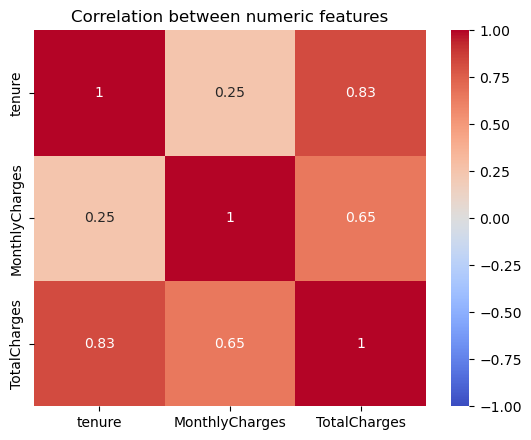

,Feature,VIF
0,TotalCharges,9.53
1,tenure,5.84
2,MonthlyCharges,3.23


In [64]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric features")
plt.tight_layout()
plt.show()


def compute_vif(data, features):
    out = []
    for f in features:
        X = data[[c for c in features if c != f]]
        r2 = LinearRegression().fit(X, data[f]).score(X, data[f])
        out.append({"Feature": f, "VIF": round(1 / (1 - r2), 2) if r2 < 1 else np.inf})
    return pd.DataFrame(out).sort_values("VIF", ascending=False).reset_index(drop=True)


compute_vif(df, numeric_cols)

Key Findings

 Key Finding: TotalCharges has the highest VIF (9.53), followed by tenure (5.84). MonthlyCharges has a lower VIF (3.23).

 Key Insight: TotalCharges and tenure contain overlapping information, so multicollinearity should be considered, especially for Logistic Regression.

 Modeling Note: TotalCharges is strongly related to tenure because longer-tenure customers naturally accumulate higher total charges.

## Key Insights: The Story in One Page

**Leadership question:** Why are customers leaving, and what can we do about it?

**Approach:** I focused on 10 business questions covering **churn size, timing, contracts, services, payments, customer groups, risk segments, and statistical validation**.

**Main takeaway:** Churn is mainly an **early-life, low-commitment** problem. Month-to-month customers in their first year show the highest risk, especially when security/support services are missing and electronic check is used. A focused segment of **916 customers (13% of the base)** accounts for **34.4% of all churners** with a **70.2% churn rate**.

### Key Findings

| Finding                                          | Evidence                             | Action                                  |
| ------------------------------------------------ | ------------------------------------ | --------------------------------------- |
| Churn is concentrated early                      | 55.5% of churners leave in year one  | Strengthen first 3–6 month onboarding   |
| Month-to-month customers churn more              | 42.7% vs 2.8% for two-year contracts | Encourage longer-term plans             |
| Security/support are associated with lower churn | 49.0% without both vs 9.0% with both | Test bundles or trials                  |
| Electronic check is a risk signal                | 45.3% churn                          | Encourage auto-pay                      |
| Fiber customers churn more                       | 41.9% vs 19.0% DSL                   | Investigate pricing and service quality |
| Risk is concentrated                             | 916 customers → 70.2% churn          | Prioritize this segment for retention   |

### Limitations

* This is **observational data**: associations do not prove causation.
* No data on service quality, complaints, competitors, or customer satisfaction.

### Modeling Decisions

1. Use **stratified train/test split**.
2. Evaluate with **Recall, Precision, F1 and ROC-AUC**, not accuracy alone.
3. Monitor collinearity between `tenure` and `TotalCharges`.
4. Use **one-hot encoding + scaling**, fitted only on training data.
5. Consider dropping features with little signal, such as `gender` and `PhoneService`.

**Next:** `Preprocessing for Model Selection`
